# the 2026 general debate in four questions

each question gets one chart and one set of world maps. every number comes from `site/data.json` (the data behind the published page) or `data/output/speeches.parquet`, so the charts agree with the site.

1. what topics came up this year
2. how this year compares with earlier debates
3. whether topics follow the challenges countries face, their geography and their alignment
4. how the press covered it, and what that says about fair representation

**colours.** a pastel UN blue `#5abdf2`, with rose `#df7a9b` and honey `#d1ad41`. they pass the colourblind checks for every pair (worst protan or deutan ΔE 12.4, normal vision 19.4). magnitude uses one ramp of UN blue. pastels are below 3:1 contrast on white, so every chart carries its numbers or a labelled legend.

**square figures.** every figure is 1:1 and is also saved as a 1800×1800 png in `notebooks/figures/`, ready to paste.

In [1]:
import json
import pathlib
from collections import Counter

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from unga_speeches.analysis import lexicons

ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
D = json.loads((ROOT / "site/data.json").read_text())
speeches = pd.DataFrame(D["speeches"])

from unga_speeches.analysis.charts import (BLUE, BLUE_INK, HONEY, INK, INK_2, MUTED, NO_SPEECH, NOT_RAISED, RAMP, ROSE, ROSE_INK, SQUARE,
                                           SURFACE, finalize, legend, style, world_map)
from unga_speeches.analysis.charts import show as show_fig
from unga_speeches.analysis.charts import world as natural_earth

style()
world = natural_earth()  # the country shapes, also read directly for income groups and the press map


raised = {name: set(speeches.loc[speeches.issues.map(lambda xs, n=name: n in xs), "iso3"]) for name in lexicons.ISSUES}
raised_n = {name: int(speeches.issues.map(lambda xs, n=name: n in xs).sum()) for name in lexicons.ISSUES}  # counts the two UN officials, who have no country
print(f"{len(speeches)} speeches in {D['year']}")

194 speeches in 2026


## 1. what was talked about this year

the share of the 194 speeches that raised each issue. an issue counts once per speech, however often it is named.

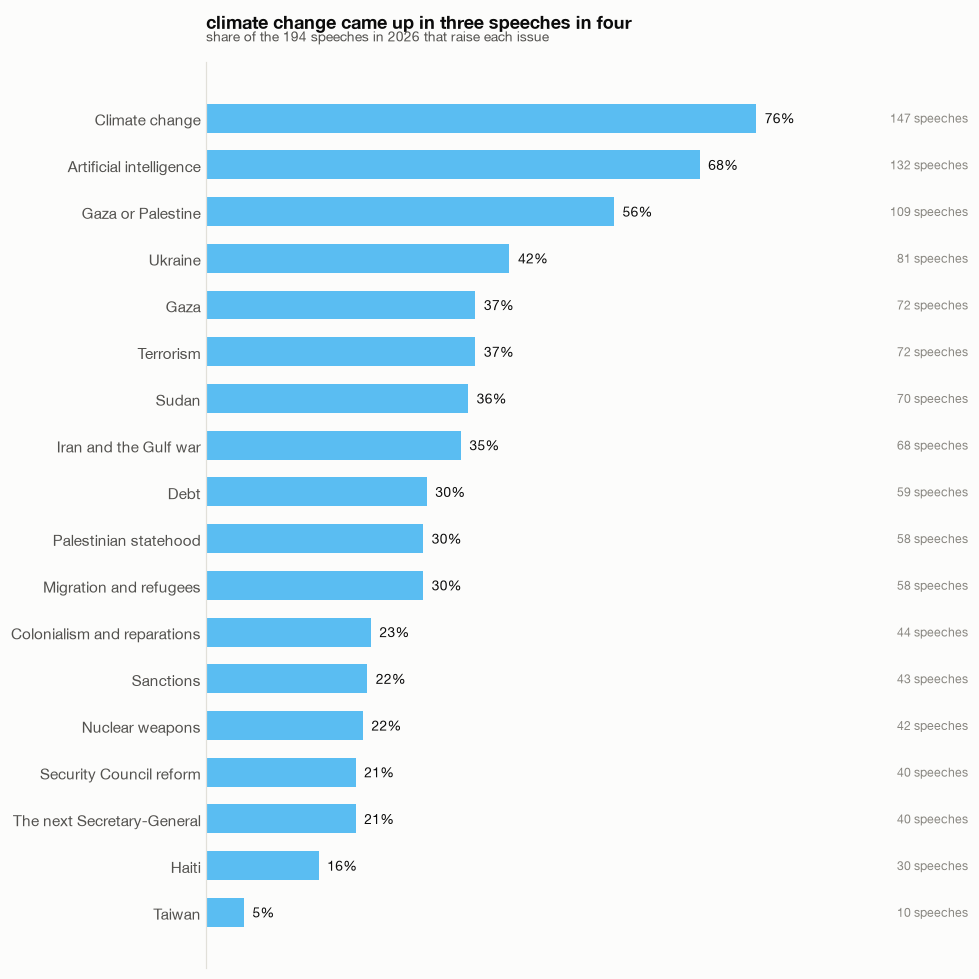

In [2]:
issues = pd.DataFrame(D["issues"]).astype({"share": float, "speeches": int}).sort_values("share")
fig, ax = plt.subplots(figsize=SQUARE)
ax.barh(issues.name, issues.share, color=BLUE, height=0.62)
for y, (s, n) in enumerate(zip(issues.share, issues.speeches)):
    ax.text(s + 0.012, y, f"{s:.0%}", va="center", fontsize=9, color=INK)
    ax.text(1.05, y, f"{n} speeches", ha="right", va="center", fontsize=8, color=MUTED)  # one right-aligned column
ax.set_xlim(0, 1.05); ax.set_xticks([]); ax.spines["bottom"].set_visible(False); ax.tick_params(length=0)
finalize(ax, "climate change came up in three speeches in four", f"share of the {len(speeches)} speeches in {D['year']} that raise each issue")
plt.tight_layout(); show_fig(fig, "1a_issues")

**where the four biggest issues were raised.** each map shows which countries raised one of the four most common issues.

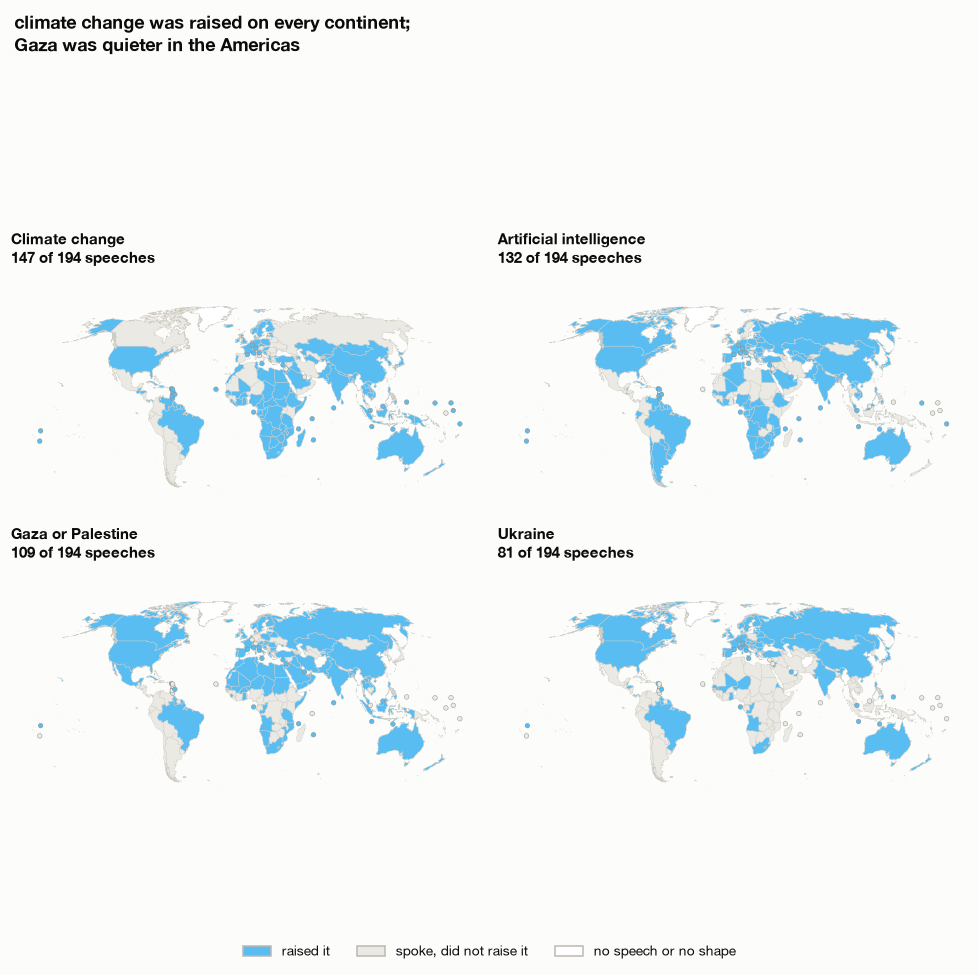

the twelve topic clusters the page finds, largest first:


,label,speeches
0,"Russia, sea lanes and nuclear risk",26
1,"Small and middle states on rules, voice and de...",25
2,"Development finance, debt and health",23
3,Gulf and Arab regional stability,18
4,"Organised crime, drugs and youth",18
5,Sahel security and African solidarity,17
6,Russia's aggression and accountability,13
7,Eurasian connectivity and neighbours,13
8,"War, missiles and military confrontation",13
9,"Pacific islands, oceans and fossil fuels",12


In [3]:
top4 = issues.name[::-1][:4].tolist()
fig, axes = plt.subplots(2, 2, figsize=SQUARE)
for ax, name in zip(axes.flat, top4):
    world_map(ax, {iso: BLUE if iso in raised[name] else NOT_RAISED for iso in speeches.iso3},
              f"{name}\n{raised_n[name]} of {len(speeches)} speeches")
fig.suptitle("climate change was raised on every continent;\nGaza was quieter in the Americas", x=0.02, ha="left", fontweight="bold", fontsize=12)
legend(fig, [("raised it", BLUE), ("spoke, did not raise it", NOT_RAISED), ("no speech or no shape", NO_SPEECH)])
plt.tight_layout(rect=(0, 0.06, 1, 0.88), h_pad=0); show_fig(fig, "1b_top_issues_map")

print("the twelve topic clusters the page finds, largest first:")
pd.DataFrame(D["topics"])[["label", "speeches"]].astype({"speeches": int}).sort_values("speeches", ascending=False).reset_index(drop=True)

## 2. how this compares with earlier debates

two views of the same numbers. six issues that tell the story keep one colour in both charts.

**the heatmap** shows how much each issue was raised every year since 1993. **the ribbon chart** shows the rank of all 18 issues, with the same six in colour. 2020 and 2021 are left out: most leaders sent a video, and the dataset holds only the chair's one-line introduction for about 210 of those speeches.

the table under the heatmap covers all 18 issues.

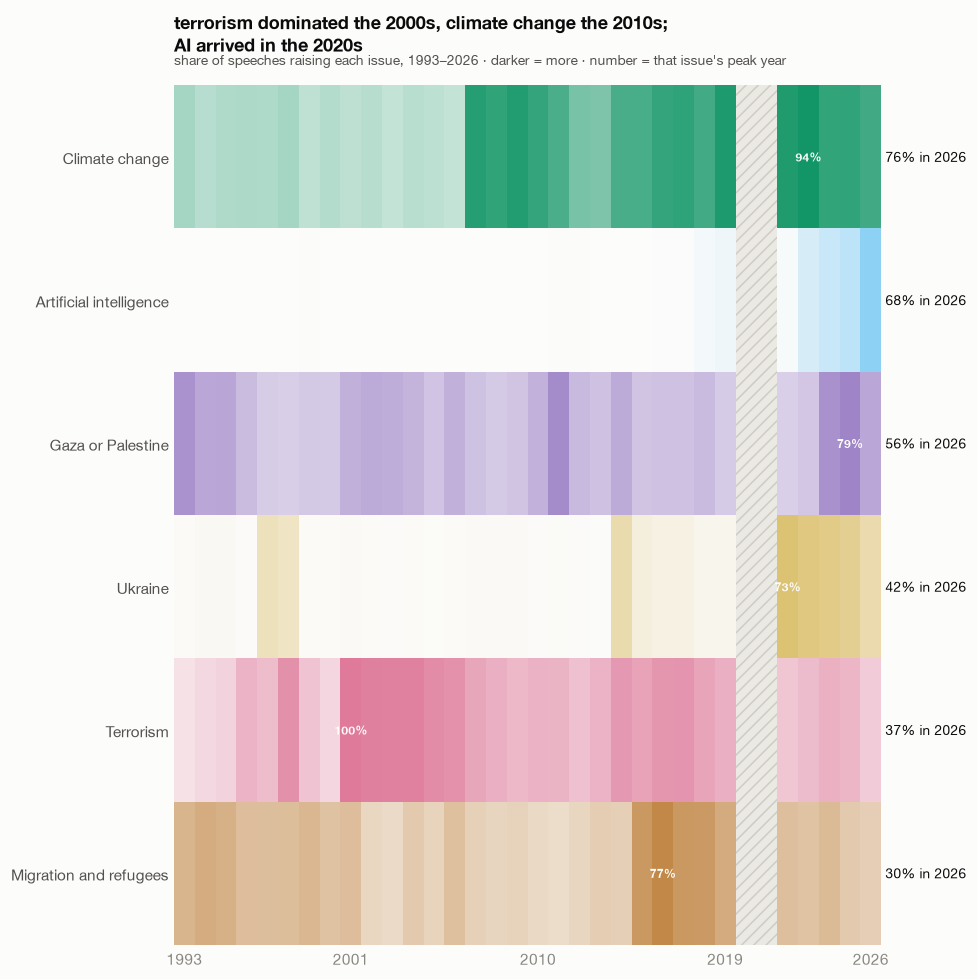

,2026,previous 10 (mean),previous high,"change, points",p (binomial)
Artificial intelligence,68%,11%,40%,+57,2e-77
Sudan,36%,12%,34%,+24,2e-17
Gaza,37%,18%,63%,+20,8e-11
Iran and the Gulf war,35%,16%,34%,+19,3e-10
The next Secretary-General,21%,4%,22%,+17,9e-17
Debt,30%,18%,36%,+13,2e-05
Gaza or Palestine,56%,46%,79%,+10,0.005
Haiti,16%,9%,19%,+7,0.002
Ukraine,42%,36%,73%,+6,0.08
Palestinian statehood,30%,26%,52%,+4,0.2


In [4]:
years = pd.DataFrame([{"year": y["year"], **y["issues"]} for y in D["years"]]).set_index("year")
order = issues.name[::-1].tolist()

# the six issues that tell the story, each with its own colour (all pairs pass the colourblind checks: worst ΔE 8.3, normal vision 17.7)
SIX = {"Climate change": "#06915f", "Artificial intelligence": BLUE, "Gaza or Palestine": "#8766bb",
       "Ukraine": HONEY, "Terrorism": ROSE, "Migration and refugees": "#b16512"}
SHOWN = [y for y in years.index if y >= 1993]
GAP = (2020, 2021)  # video years: the text is missing


def tint(colour, v):
    """the issue's colour mixed with the page surface: 0 is the surface, 1 is the full colour."""
    c, w = np.array(matplotlib.colors.to_rgb(colour)), np.array(matplotlib.colors.to_rgb(SURFACE))
    return w + (c - w) * v


fig, ax = plt.subplots(figsize=SQUARE)
cells = np.ones((len(SIX), len(SHOWN), 3))
for i, (issue, colour) in enumerate(SIX.items()):
    for j, yr in enumerate(SHOWN):
        cells[i, j] = matplotlib.colors.to_rgb(NOT_RAISED) if yr in GAP else tint(colour, float(years.at[yr, issue]))
ax.imshow(cells, aspect="auto")
for j, yr in enumerate(SHOWN):
    if yr in GAP:
        ax.add_patch(plt.Rectangle((j - .5, -.5), 1, len(SIX), facecolor="none", hatch="///", edgecolor="#cfccc4", lw=0))
for i, issue in enumerate(SIX):
    shares = years.loc[[y for y in SHOWN if y not in GAP], issue].astype(float)
    peak = shares.idxmax()
    if peak != D["year"]:  # the 2026 value is already written at the right
        ax.text(SHOWN.index(peak), i, f"{shares[peak]:.0%}", ha="center", va="center", fontsize=8, color=SURFACE, fontweight="bold")
    ax.text(len(SHOWN) - 0.3, i, f"{shares[D['year']]:.0%} in {D['year']}", va="center", fontsize=9, color=INK)
ax.set_yticks(range(len(SIX)), list(SIX)); ax.tick_params(length=0)
ax.set_xticks([SHOWN.index(y) for y in (1993, 2001, 2010, 2019, 2026)], [1993, 2001, 2010, 2019, 2026])
ax.set_xlim(-0.5, len(SHOWN) + 3.2)
for s in ax.spines.values():
    s.set_visible(False)
finalize(ax, "terrorism dominated the 2000s, climate change the 2010s;\nAI arrived in the 2020s",
         "share of speeches raising each issue, 1993–2026 · darker = more · number = that issue's peak year")
plt.tight_layout(); show_fig(fig, "2a_issues_by_year")

# how unusual is 2026 against the debates before it (2014–2025, without 2020 and 2021), for all 18 issues
base = years.loc[[y for y in range(2014, 2026) if y not in GAP], order].astype(float)
now = years.loc[D["year"], order].astype(float)
n = int(D["years"][-1]["speeches"])
cmp = pd.DataFrame({"2026": now, "previous 10 (mean)": base.mean(), "previous high": base.max()})
cmp["change, points"] = (cmp["2026"] - cmp["previous 10 (mean)"]) * 100
cmp["p (binomial)"] = [stats.binomtest(round(now[i] * n), n, max(min(base[i].mean(), .999), .001)).pvalue for i in order]
cmp.sort_values("change, points", ascending=False).style.format(
    {"2026": "{:.0%}", "previous 10 (mean)": "{:.0%}", "previous high": "{:.0%}", "p (binomial)": "{:.1g}", "change, points": "{:+.0f}"})

**how the ranking moved.** each issue's rank among all 18, by the share of speeches that raised it, at roughly five-year steps. a band's thickness is that share. the heatmap's six issues keep their colours; the other twelve are grey.

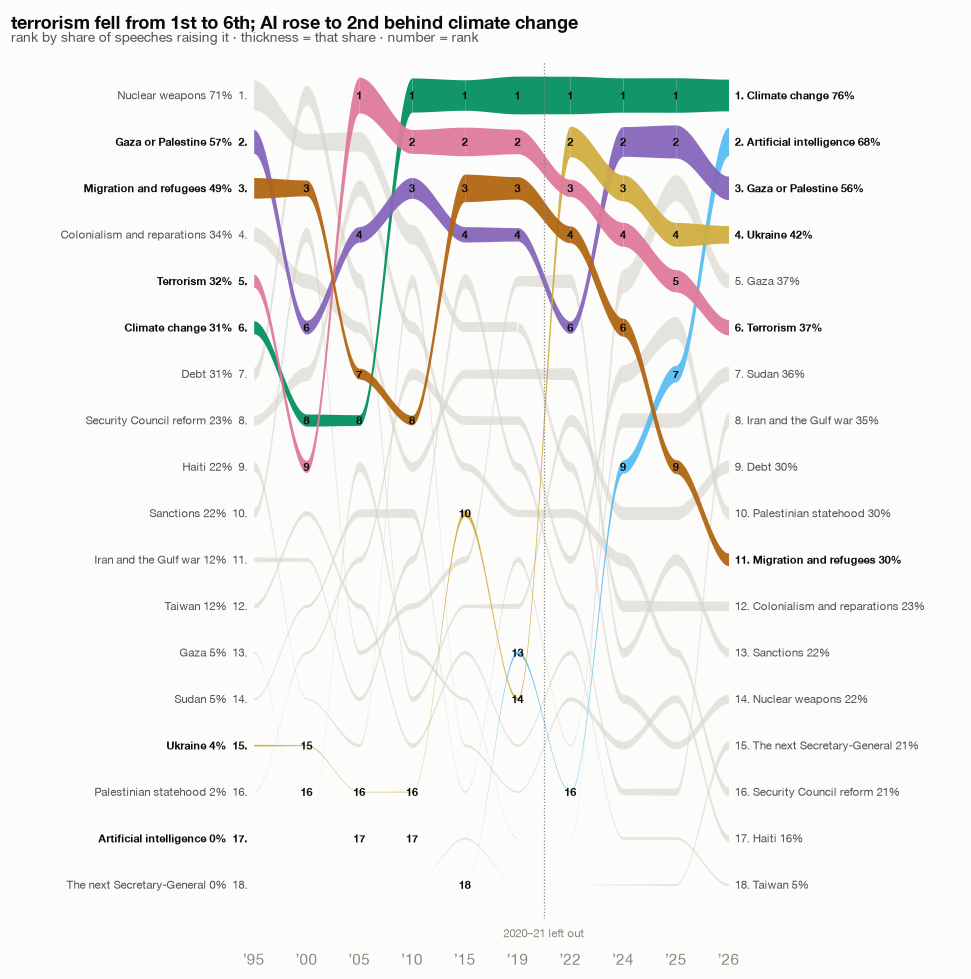

year,1995,2000,2005,2010,2015,2019,2022,2024,2025,2026
Climate change,6,8,8,1,1,1,1,1,1,1
Artificial intelligence,17,16,17,17,18,13,16,9,7,2
Gaza or Palestine,2,6,4,3,4,4,6,2,2,3
Ukraine,15,15,16,16,10,14,2,3,4,4
Terrorism,5,9,1,2,2,2,3,4,5,6
Migration and refugees,3,3,7,8,3,3,4,6,9,11


In [5]:
STEPS = [1995, 2000, 2005, 2010, 2015, 2019, 2022, 2024, 2025, 2026]
share = years.loc[STEPS, order].astype(float)
rank = share.rank(axis=1, ascending=False, method="first")
HIGHLIGHT = SIX  # the heatmap's six issues, in the same colours


def ribbon(ax, x0, x1, y0, y1, w0, w1, colour, alpha):
    """a sankey-style band from (x0, y0) to (x1, y1) along a smooth s-curve, its width easing from w0 to w1."""
    t = np.linspace(0, 1, 40)
    e = 3 * t**2 - 2 * t**3
    x, y, w = x0 + (x1 - x0) * t, y0 + (y1 - y0) * e, w0 + (w1 - w0) * e
    ax.fill_between(x, y - w / 2, y + w / 2, color=colour, alpha=alpha, lw=0)


fig, ax = plt.subplots(figsize=SQUARE)
for issue in order[::-1] if False else sorted(order, key=lambda i: i in HIGHLIGHT):
    colour, alpha = HIGHLIGHT.get(issue, "#d6d3cb"), (0.95 if issue in HIGHLIGHT else 0.6)
    for i in range(len(STEPS) - 1):
        a, b = STEPS[i], STEPS[i + 1]
        ribbon(ax, i, i + 1, rank.at[a, issue], rank.at[b, issue], 0.9 * share.at[a, issue], 0.9 * share.at[b, issue], colour, alpha)
    for x, yr, ha in [(-0.12, STEPS[0], "right"), (len(STEPS) - 1 + 0.12, STEPS[-1], "left")]:
        ax.text(x, rank.at[yr, issue], f"{int(rank.at[yr, issue])}. {issue} {share.at[yr, issue]:.0%}" if ha == "left" else f"{issue} {share.at[yr, issue]:.0%}  {int(rank.at[yr, issue])}.", ha=ha, va="center", fontsize=7.5,
                color=INK if issue in HIGHLIGHT else INK_2, fontweight="bold" if issue in HIGHLIGHT else "normal")
for issue in HIGHLIGHT:
    for i, yr in list(enumerate(STEPS))[1:-1]:
        ax.text(i, rank.at[yr, issue], f"{int(rank.at[yr, issue])}", ha="center", va="center", fontsize=7.5, color=INK, fontweight="bold")
ax.axvline(5.5, color=MUTED, lw=0.8, ls=":")
ax.text(5.5, 18.9, "2020–21 left out", ha="center", va="top", fontsize=7.5, color=MUTED, backgroundcolor=SURFACE)
ax.set_xticks(range(len(STEPS)), [f"’{str(y)[2:]}" for y in STEPS])
ax.set_yticks([])
ax.set_ylim(19.3, 0.3)
ax.set_xlim(-4.6, len(STEPS) + 3.4)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)
r = rank.astype(int)
finalize(ax, f"terrorism fell from {r.at[2005, 'Terrorism']}st to {r.at[2026, 'Terrorism']}th; AI rose to {r.at[2026, 'Artificial intelligence']}nd behind climate change",
         "rank by share of speeches raising it · thickness = that share · number = rank")
plt.tight_layout(); show_fig(fig, "2b_rank_flow")

r.T.loc[list(HIGHLIGHT)]

**who started talking about AI this year.** each country's 2025 and 2026 speech, run through the same issue word list. rose marks a country that raised AI in 2026 but not in 2025.

2025's English is mostly the UN interpreters' words, transcribed. 2026's is mostly the text each delegation filed. the rise holds within each kind of text, so it is not an artefact of the change.

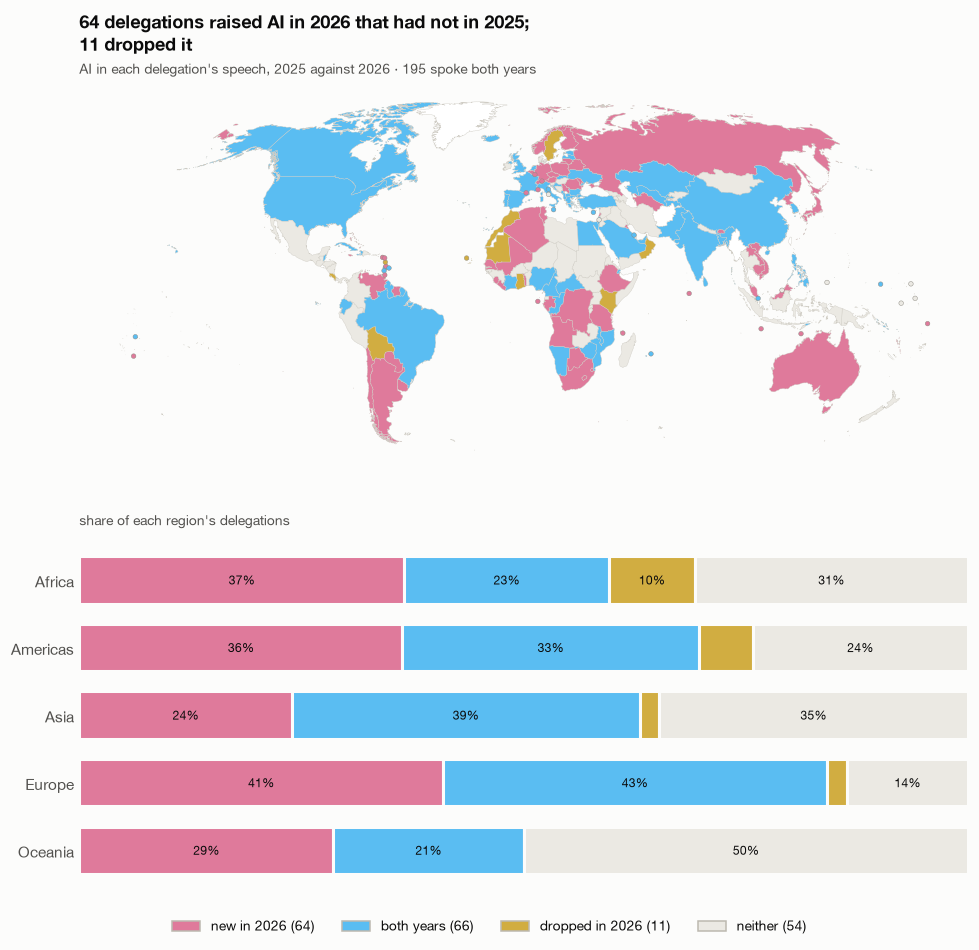

In [6]:
texts = pd.read_parquet(ROOT / "data/output/speeches.parquet", columns=["session", "iso3", "english_text_clean"])
texts = texts[texts.session.isin([80, 81]) & texts.english_text_clean.notna()]
ai = {s: set(g.iso3[g.english_text_clean.map(lambda t: lexicons.issues(t)["Artificial intelligence"])]) for s, g in texts.groupby("session")}
both = set(texts[texts.session == 80].iso3) & set(texts[texts.session == 81].iso3)
state = {iso: ("both years" if iso in ai[80] and iso in ai[81] else "new in 2026" if iso in ai[81] else "dropped in 2026" if iso in ai[80] else "neither")
         for iso in both}
colours = {"new in 2026": ROSE, "both years": BLUE, "dropped in 2026": HONEY, "neither": NOT_RAISED}
counts = pd.Series(state).value_counts()

fig, (ax, bx) = plt.subplots(2, 1, figsize=SQUARE, gridspec_kw={"height_ratios": [1.5, 1]})
world_map(ax, {iso: colours[s] for iso, s in state.items()})
finalize(ax, f"{counts.get('new in 2026', 0)} delegations raised AI in 2026 that had not in 2025;\n{counts.get('dropped in 2026', 0)} dropped it",
         f"AI in each delegation's speech, 2025 against 2026 · {len(both)} spoke both years")
by_region = pd.crosstab(pd.Series(state).index.map(dict(zip(speeches.iso3, speeches.region))).fillna("UN"), pd.Series(state).values, normalize="index")
by_region = by_region.reindex(columns=list(colours)).fillna(0).loc[["Africa", "Americas", "Asia", "Europe", "Oceania"]]
left = np.zeros(len(by_region))
for k, c in colours.items():
    bx.barh(by_region.index, by_region[k], left=left, color=c, edgecolor=SURFACE, linewidth=2, height=0.7)
    for y, (l, v) in enumerate(zip(left, by_region[k])):
        if v >= 0.08:
            bx.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=8, color=INK)
    left += by_region[k].values
bx.invert_yaxis(); bx.set_xlim(0, 1); bx.set_xticks([]); bx.tick_params(length=0)
for side in ("left", "bottom"):
    bx.spines[side].set_visible(False)
bx.set_title("share of each region's delegations", fontsize=9, color=INK_2, fontweight="normal")
legend(fig, [(f"{k} ({counts.get(k, 0)})", c) for k, c in colours.items()])
plt.tight_layout(rect=(0, 0.05, 1, 1)); show_fig(fig, "2c_ai_map")

## 3. do topics follow challenges, geography and alignment

each cell is the share of speeches from a group that raised the issue.

- **geography:** the UN's five regions.
- **challenges:** the World Bank income group in Natural Earth, as a rough stand-in for debt, climate exposure and capacity.
- **alignment:** NATO members, BRICS members, and everyone else. both lists are typed in below.

a star marks an issue whose share differs between the groups in that panel more than chance would allow (chi-square test, p < 0.001 after a Bonferroni correction for 18 issues).

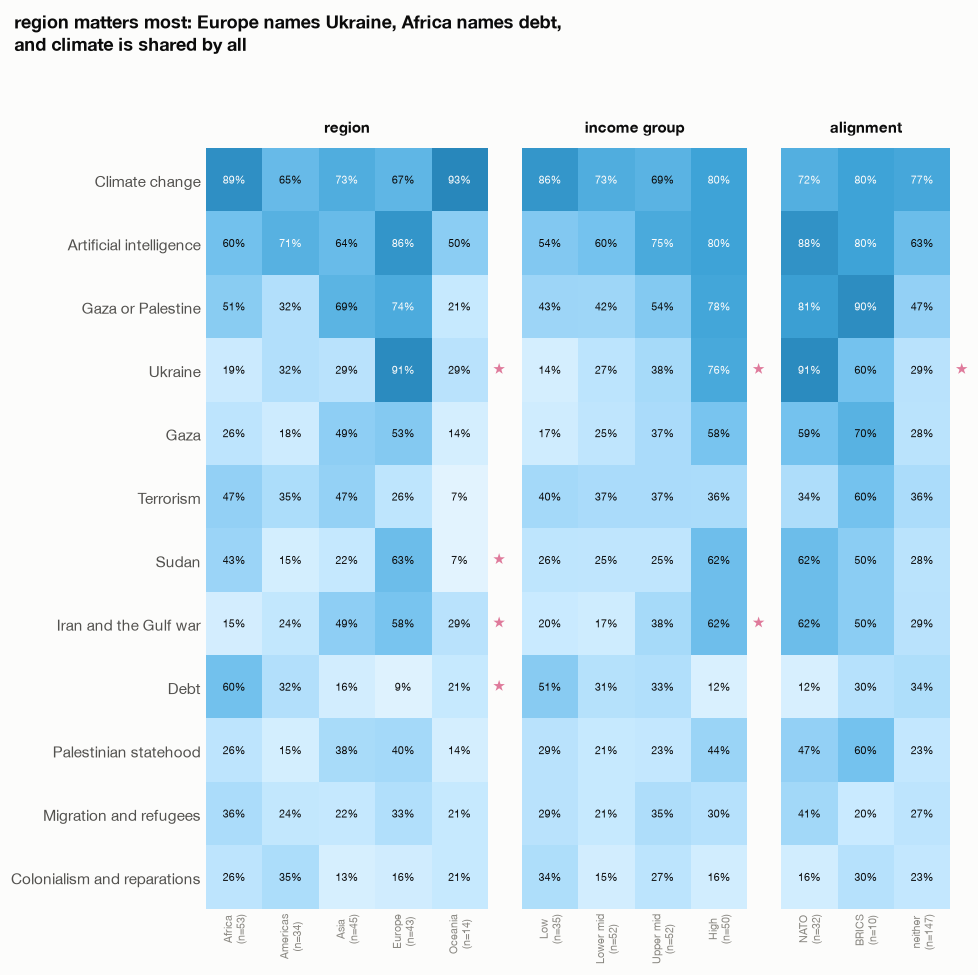

,panel,issue,cramér's v,p (bonferroni)
0,region,Ukraine,0.56,7e-11
1,alignment,Ukraine,0.48,6e-09
2,region,Haiti,0.48,2e-07
3,income group,Ukraine,0.46,2e-07
4,region,Debt,0.44,3e-06
5,region,Sudan,0.40,7e-05
6,income group,Iran and the Gulf war,0.38,0.0001
7,region,Iran and the Gulf war,0.37,0.0008
8,region,Gaza or Palestine,0.36,0.002
9,income group,Sudan,0.34,0.001


In [7]:
NATO = set("ALB BEL BGR CAN HRV CZE DNK EST FIN FRA DEU GRC HUN ISL ITA LVA LTU LUX MNE NLD MKD NOR POL PRT ROU SVK SVN ESP SWE TUR GBR USA".split())
BRICS = set("BRA RUS IND CHN ZAF EGY ETH IRN ARE IDN".split())

income = dict(zip(world.ISO_A3_EH, world.INCOME_GRP.str[3:].str.replace(r": (non)?OECD", "", regex=True)))
states = speeches[speeches.status == "member_state"].copy()
states["income"] = states.iso3.map(income)
states["alignment"] = np.where(states.iso3.isin(NATO), "NATO", np.where(states.iso3.isin(BRICS), "BRICS", "neither"))
for name in order:
    states[name] = states.issues.map(lambda xs, name=name: name in xs)

panels = {
    "region": ("region", ["Africa", "Americas", "Asia", "Europe", "Oceania"]),
    "income group": ("income", ["Low income", "Lower middle income", "Upper middle income", "High income"]),
    "alignment": ("alignment", ["NATO", "BRICS", "neither"]),
}
short = lambda g: g.replace(" income", "").replace("Lower middle", "Lower mid").replace("Upper middle", "Upper mid")
show = order[:12]
fig, axes = plt.subplots(1, 3, figsize=SQUARE, sharey=True, gridspec_kw={"width_ratios": [5, 4, 3]})
for ax, (title, (col, groups)) in zip(axes, panels.items()):
    sub = states[states[col].isin(groups)]
    m = sub.groupby(col)[show].mean().loc[groups].T
    ax.imshow(m.values, aspect="auto", cmap=RAMP, vmin=0, vmax=1)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.values[i, j]
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color=SURFACE if v > .7 else INK)
    sig = [sub[i].nunique() > 1 and stats.chi2_contingency(pd.crosstab(sub[col], sub[i]))[1] * len(order) < 1e-3 for i in show]
    ax.set_yticks(range(len(show)), show)
    ax.set_xticks(range(len(groups)), [f"{short(g)}\n(n={int((sub[col] == g).sum())})" for g in groups], fontsize=7, rotation=90)
    ax.set_title(title, fontsize=10, loc="center"); ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    for k, s in enumerate(sig):
        if s: ax.text(len(groups) - .42, k, "★", va="center", fontsize=10, color=ROSE, fontfamily="DejaVu Sans")
fig.suptitle("region matters most: Europe names Ukraine, Africa names debt,\nand climate is shared by all", x=0.02, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.95)); show_fig(fig, "3a_issues_by_group")

# the effect sizes behind the stars: cramér's v per issue and panel
rows = []
for title, (col, groups) in panels.items():
    sub = states[states[col].isin(groups)]
    for i in order:
        if sub[i].nunique() < 2: continue
        t = pd.crosstab(sub[col], sub[i]); chi2, p, *_ = stats.chi2_contingency(t)
        rows.append({"panel": title, "issue": i, "cramér's v": np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1))), "p (bonferroni)": min(1, p * len(order))})
pd.DataFrame(rows).sort_values("cramér's v", ascending=False).head(12).reset_index(drop=True).style.format({"cramér's v": "{:.2f}", "p (bonferroni)": "{:.1g}"})

**two of the strongest splits, on the map.** Ukraine is the issue where region explains the most. debt is the strongest split that falls along income (the table above).

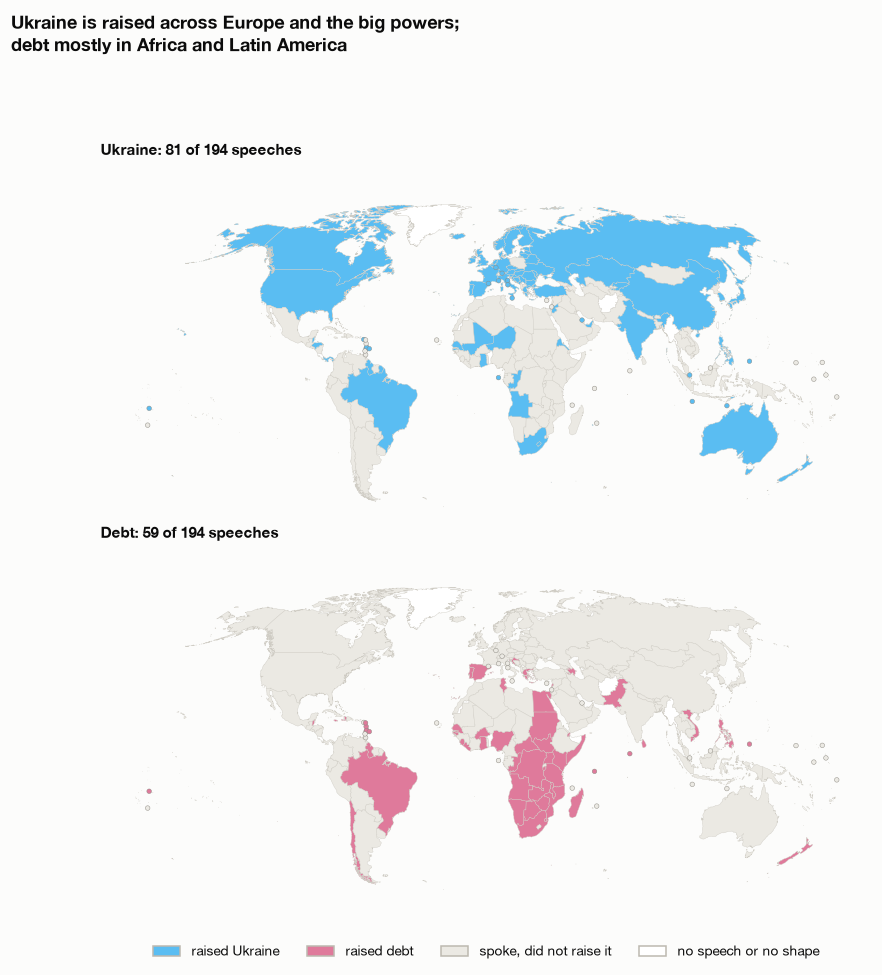

In [8]:
fig, axes = plt.subplots(2, 1, figsize=SQUARE)
for ax, name, colour in zip(axes, ["Ukraine", "Debt"], [BLUE, ROSE]):
    world_map(ax, {iso: colour if iso in raised[name] else NOT_RAISED for iso in speeches.iso3}, f"{name}: {raised_n[name]} of {len(speeches)} speeches")
fig.suptitle("Ukraine is raised across Europe and the big powers;\ndebt mostly in Africa and Latin America", x=0.02, ha="left", fontweight="bold", fontsize=12)
legend(fig, [("raised Ukraine", BLUE), ("raised debt", ROSE), ("spoke, did not raise it", NOT_RAISED), ("no speech or no shape", NO_SPEECH)])
plt.tight_layout(rect=(0, 0.06, 1, 0.92)); show_fig(fig, "3b_ukraine_debt_map")

**what was said on each topic.** for each topic, every 2026 sentence that raises it, grouped into three themes, then the six sentences least like anything another speaker said.

- **themes:** the sentences are clustered by the words they share; each theme lists its most typical words.
- **distinctive:** each sentence is compared with every other speaker's sentences on the topic, by the words they share (tf-idf with a 50-dimension reduction, so related words count as close). the quotes are the sentences whose nearest match from another speaker is furthest away, at most one per speaker.
- **checked:** every quote is matched word for word against the source text before it is printed.

this measures shared wording, not meaning in a deeper sense, so two sentences that make the same point in different words can both count as distinctive.

In [9]:
import re
import textwrap

from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize

# every sentence of every 2026 speech, with who said it
texts = pd.read_parquet(ROOT / "data/output/speeches.parquet", columns=["session", "iso3", "english_text_clean", "english_text"])
texts = texts[texts.session == D["session"]].set_index("iso3")
UN_ISO = {"secretary-general-united-nations": "UN-SG", "president-general-assembly-opening": "UN-PGA"}
FURNITURE = re.compile(r"official website|check against delivery|[A-Z]{3,}(?: [A-Z]{3,}){2,}")
sentences = []
for _, r in speeches.iterrows():
    iso = r.iso3 or UN_ISO.get(r.slug)
    if iso not in texts.index or not isinstance(texts.at[iso, "english_text_clean"], str):
        continue
    for s in lexicons.SENTENCE.split(texts.at[iso, "english_text_clean"]):
        s = lexicons.TRAILING_NUMBER.sub("", s.strip())  # drop the paragraph number some statements print after a sentence
        if 12 <= len(s.split()) <= 60 and not FURNITURE.search(s):
            sentences.append({"slug": r.slug, "delegation": r.delegation, "speaker": r.speaker, "title": r.title,
                              "kind": r.english_kind, "sentence": s, "verbatim": texts.at[iso, "english_text"]})
sentences = pd.DataFrame(sentences)
squash = lambda t: re.sub(r"\s+", " ", t).strip()


def what_was_said(topic, themes=3, quotes=6):
    """the main themes in the sentences that raise a topic, then the sentences least like any other speaker's."""
    t = sentences[sentences.sentence.map(lambda s: bool(lexicons.issue_pattern(topic).search(s)))].reset_index(drop=True)
    vec = TfidfVectorizer(stop_words="english", sublinear_tf=True, min_df=2, ngram_range=(1, 2))
    X = vec.fit_transform(t.sentence)
    svd = TruncatedSVD(min(50, X.shape[1] - 1), random_state=0)
    Z = normalize(svd.fit_transform(X))
    sim = Z @ Z.T
    slugs = t.slug.to_numpy(dtype=object)
    same = slugs[:, None] == slugs[None, :]
    nearest = np.where(same, -1, sim).max(axis=1)  # closest sentence from any other speaker
    t["distinctiveness"] = 1 - nearest

    print(f"{topic.upper()}: {len(t)} sentences in {t.slug.nunique()} speeches\n")
    km = KMeans(themes, n_init=10, random_state=0).fit(Z)
    centres = svd.inverse_transform(km.cluster_centers_)
    terms = np.array(vec.get_feature_names_out())
    print("main themes (most typical words in each group of sentences):")
    for k in np.argsort(-np.bincount(km.labels_)):
        words = [w for w in terms[np.argsort(-centres[k])] if not lexicons.issue_pattern(topic).search(w)][:6]
        print(f"  · {', '.join(words)}  ({(km.labels_ == k).sum()} sentences, {t.slug[km.labels_ == k].nunique()} speeches)")

    print("\nthe most distinctive sentences (least like any other speaker's), one per speaker:")
    picked = []
    for i in t.sort_values("distinctiveness", ascending=False).index:
        if t.at[i, "slug"] in set(t.loc[picked, "slug"]) or (picked and sim[i, picked].max() > 0.5):
            continue
        if squash(t.at[i, "sentence"]) not in squash(t.at[i, "verbatim"]):
            continue  # quote only what appears word for word in the source text
        picked.append(i)
        if len(picked) == quotes:
            break
    for i in picked:
        r = t.loc[i]
        source = "the UN interpreters' English" if r.kind == "transcript" else "the delegation's English text"
        print(textwrap.fill(f"“{r.sentence}”", 110, initial_indent="  ", subsequent_indent="   "))
        print(f"     — {r.speaker}, {r.title}, {r.delegation} · {source}\n")
    print()


for topic in ["Ukraine", "Debt", "Climate change", "Artificial intelligence", "Gaza or Palestine"]:
    what_was_said(topic)

UKRAINE: 191 sentences in 76 speeches

main themes (most typical words in each group of sentences):
  · support, people, sudan, gaza, middle east, middle  (108 sentences, 57 speeches)
  · war, russia, russia war, aggression, years, end  (61 sentences, 33 speeches)
  · sovereignty, territorial integrity, territorial, integrity, sovereignty territorial, peace  (22 sentences, 21 speeches)

the most distinctive sentences (least like any other speaker's), one per speaker:
  “The Ukrainian regime is undermining a cornerstone of the UN charter, not respecting human rights nor
   fundamental freedoms irrespective of race, sex, language or religion.”
     — Sergey Lavrov, Minister for Foreign Affairs, Russian Federation · the UN interpreters' English

  “Ukraine must have a decisive say in its own future and Europe cannot be absent from negotiations.”
     — Kyriakos Mitsotakis, Prime Minister, Greece · the delegation's English text

  “My fellow leaders, While it is the situation in Ukraine an

ARTIFICIAL INTELLIGENCE: 359 sentences in 120 speeches

main themes (most typical words in each group of sentences):
  · intelligence, artificial, development, new, digital, technologies  (158 sentences, 92 speeches)
  · ai, human, people, risks, global, new  (137 sentences, 48 speeches)
  · international, governance, global, artificial, intelligence, ai  (64 sentences, 45 speeches)

the most distinctive sentences (least like any other speaker's), one per speaker:
  “The Republic of Korea is pursuing an AI transformation that will ensure stronger protection of fundamental
   rights across fields such as social security, labor, housing, and culture, beginning with our ‘AI Universal
   Basic Health’ program.”
     — Lee Jae Myung, President, Republic of Korea · the delegation's English text

  “The real productivity gains from AI comes not from the IT department, but from our businesses and workers
   having the skills, the tools, and the wherewithal to re-engineer their work processes f

**do speakers connect AI and climate change?** rarely, and never as harm. 93 speeches raise both, but only 15 name them in the same sentence, and no speech names AI's energy use or emissions as a climate problem. where the two meet, it is in one of four ways:

- **side by side, as the era's big challenges.** Finland, Ethiopia, Switzerland, Australia, Tanzania and Saint Kitts and Nevis list them together.
- **AI as a tool against climate change.** the Republic of Korea, Malawi, Vanuatu, Micronesia, Andorra, Greece and Samoa (for energy planning) say AI can help.
- **the resources behind AI, seen as an opportunity.** the Democratic Republic of the Congo, Argentina and Botswana point to their critical minerals and energy; Bhutan's hydropower and Lesotho's terrain would host data centres. Malaysia warns that the Global South "cannot simply become a destination for data centres, while decisions about A.I. are made elsewhere".
- **dismissed together.** the United States says the people warning that "AI is going to kill us all" are "the very same people who said we'll all be dead in 12 years because of global warming".

the reading above is by hand; the cell below prints every sentence it rests on.

In [10]:
AI, CLIMATE = lexicons.issue_pattern("Artificial intelligence"), lexicons.issue_pattern("Climate change")
FOOTPRINT = re.compile(r"data cent|energy[- ]hungry|power[- ]hungry|carbon footprint|energy consumption|critical mineral", re.I)
s = sentences.assign(ai=sentences.sentence.map(lambda x: bool(AI.search(x))), climate=sentences.sentence.map(lambda x: bool(CLIMATE.search(x))))
together = s[s.ai & s.climate]
print(f"speeches raising AI: {s[s.ai].slug.nunique()} · climate change: {s[s.climate].slug.nunique()} · both, anywhere in the speech: "
      f"{len(set(s[s.ai].slug) & set(s[s.climate].slug))}")
print(f"sentences naming AI and climate together: {len(together)}, in {together.slug.nunique()} speeches\n")
for _, r in together.iterrows():
    print(textwrap.fill(f"“{r.sentence}”", 110, initial_indent="  ", subsequent_indent="   "))
    print(f"     — {r.speaker}, {r.title}, {r.delegation}\n")
print("sentences on data centres, critical minerals or AI's energy use:\n")
for _, r in s[s.sentence.str.contains(FOOTPRINT)].iterrows():
    print(textwrap.fill(f"“{r.sentence}”", 110, initial_indent="  ", subsequent_indent="   "))
    print(f"     — {r.speaker}, {r.title}, {r.delegation}\n")

speeches raising AI: 120 · climate change: 136 · both, anywhere in the speech: 93
sentences naming AI and climate together: 16, in 15 speeches

  “We highlight his exemplary contribution as a man of dialogue, an advocate of the United Nations Charter and
   of International Law, a tireless advocate of the need to protect the planet from the harmful effects of
   climate change, and a champion of the global debate on the global governance of artificial intelligence.”
     — João Manuel Gonçalves Lourenço, President, Angola

  “The voice of Africans must be heard in all circumstances, at all times, in strategic decision-making
   processes on issues of peace, global security, financing for development, as well as climate issues and the
   global governance of artificial intelligence.”
     — João Manuel Gonçalves Lourenço, President, Angola

  “We need multilateralism in order to address our shared agenda, ranging from armed conflicts and climate
   change to sustainable development and 

In [11]:
# the naming network: do delegations name states in their own region, bloc or theory lean more than chance?
h = pd.DataFrame(D["network"]["homophily"]).T[["observed", "chance_rewired", "ratio", "p", "pairs"]]
h.columns = ["same-group share of names", "expected by chance", "ratio", "p", "pairs"]
h

,same-group share of names,expected by chance,ratio,p,pairs
region,0.436,0.229,1.91,0.0,1160.0
lean,0.397,0.316,1.25,0.0,537.0
bloc,0.361,0.233,1.55,0.0,1193.0


## 4. how the press covered it, and whether that was fair

**left:** how often the press and the speeches raise each issue, per 1,000 words. rose issues got clearly more press than podium time, blue ones clearly less, and grey ones are too close to call. "clearly" means the 90% interval from resampling the articles 500 times stays on one side of the line. the issues near the line without a label are in the table at the end.

**right:** how the press's attention to other countries was spread across the 191 speaking delegations. if every delegation got the same share, the curve would follow the dashed line. attention is measured in each news country, counting only mentions of other countries, then averaged across the 31 news countries whose outlets name at least 10 other delegations.

**what this measures, and what it does not.** "attention" counts paragraphs that name a delegation during debate week. only a third to a half of those paragraphs also mention the UN or a speech, so it is attention to the country, not to its speech.

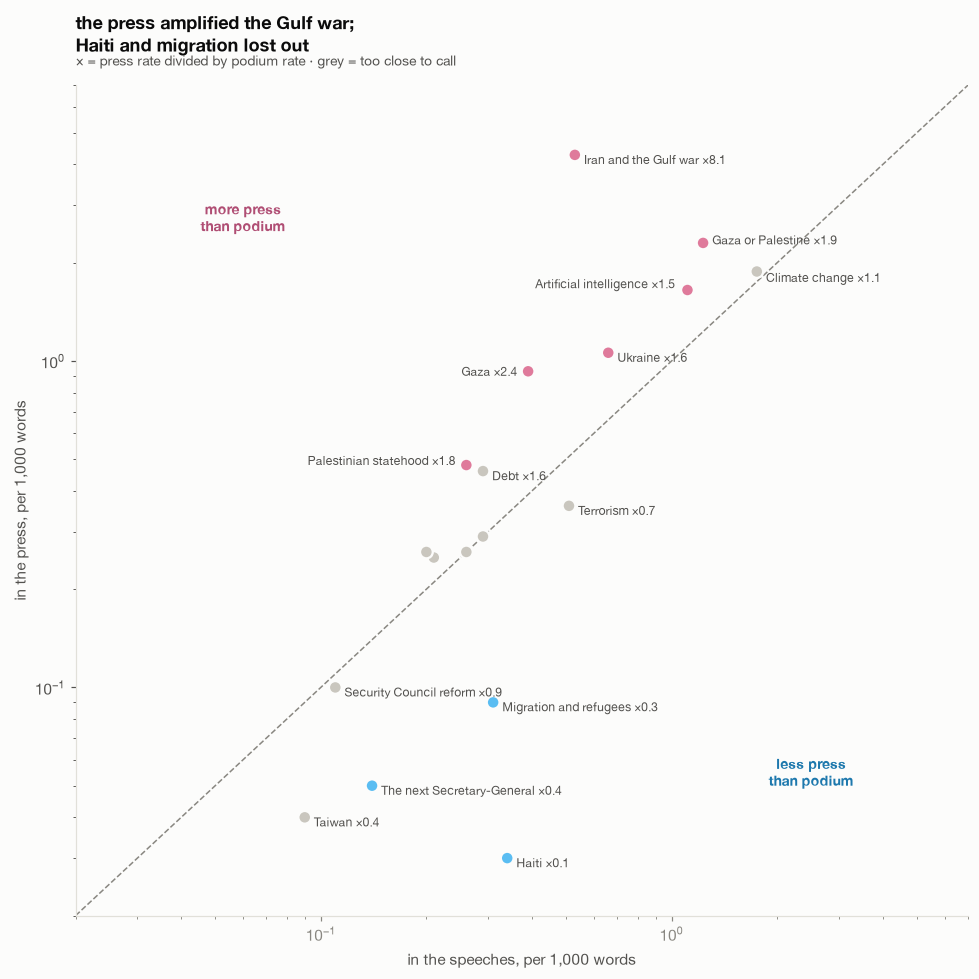

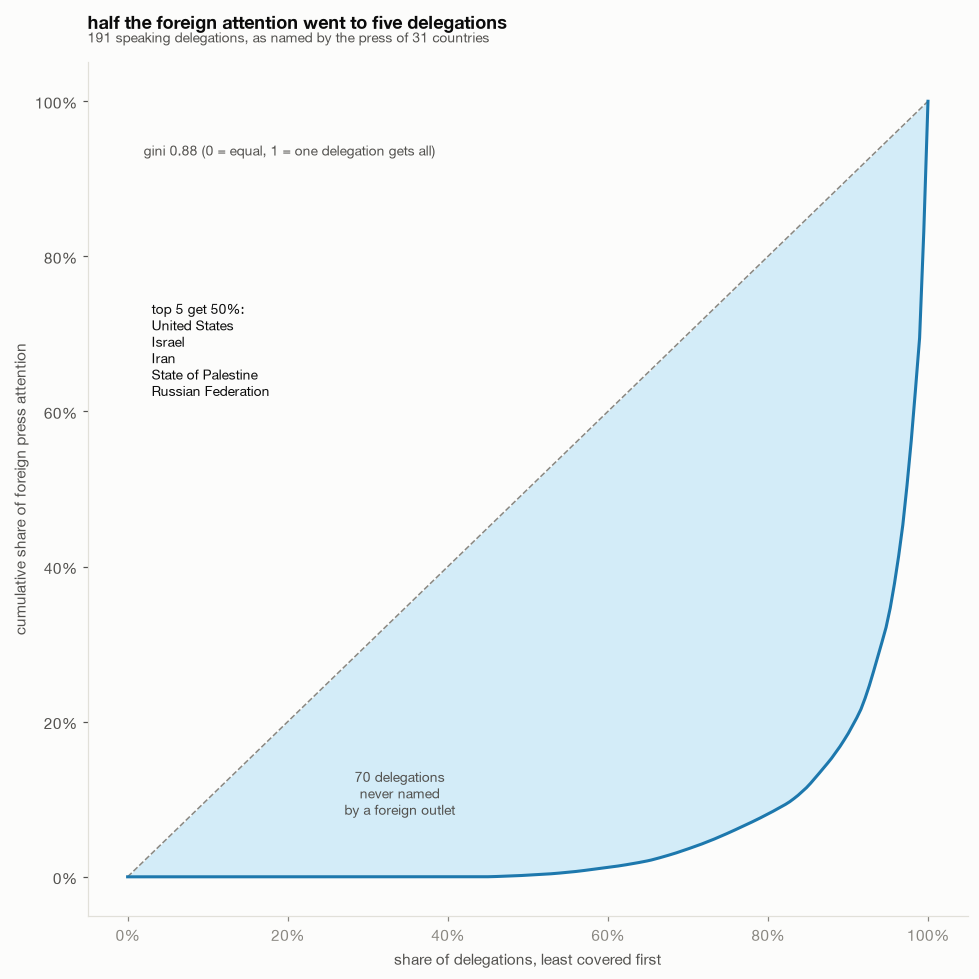

In [12]:
pi = pd.DataFrame(D["press"]["issues"]).astype({"podium_per_1000": float, "press_per_1000": float})
pi = pi[(pi.podium_per_1000 > 0) & (pi.press_per_1000 > 0)].copy()
pi["ratio"] = pi.press_per_1000 / pi.podium_per_1000

# resample the articles to see which ratios are clearly above or below 1
from unga_speeches.analysis import press
articles, _ = press.panel(press.load_news(D["session"]))
def press_rates(sample):
    text = " ".join(p for a in sample for p in a["paragraphs"])
    return pd.Series(lexicons.issue_counts(text)) * 1000 / max(1, len(text.split()))
rng = np.random.default_rng(0)
boot = pd.DataFrame([press_rates([articles[i] for i in rng.integers(0, len(articles), len(articles))]) for _ in range(500)])
pi["low"] = pi.issue.map(boot.quantile(0.05)) / pi.podium_per_1000
pi["high"] = pi.issue.map(boot.quantile(0.95)) / pi.podium_per_1000
pi["verdict"] = np.where(pi.low > 1, "more press", np.where(pi.high < 1, "less press", "too close to call"))
att = pd.DataFrame(D["press"]["attention"]["rows"]).astype({"foreign_share": float})
n_del = int(D["press"]["attention"]["delegations"])
shares = np.sort(np.r_[att.foreign_share.values, np.zeros(n_del - len(att))])
lorenz = np.r_[0, np.cumsum(shares / shares.sum())]
gini = 1 - 2 * np.trapezoid(lorenz, dx=1 / n_del)
top5 = att.nlargest(5, "foreign_share")
name_of = speeches.set_index("slug").delegation.to_dict() | {"iran-islamic-republic": "Iran", "united-states-america": "United States"}

# hand-placed label offsets (points) so the labels do not collide
OFFSET = {"Iran and the Gulf war": (6, -3), "Gaza or Palestine": (6, 2), "Climate change": (6, -4), "Artificial intelligence": (-8, 4, "right"),
          "Gaza": (-7, 0, "right"), "Ukraine": (6, -3), "Debt": (6, -3), "Palestinian statehood": (-7, 3, "right"), "Terrorism": (6, -3),
          "Migration and refugees": (6, -3), "Haiti": (6, -3), "Taiwan": (6, -3), "The next Secretary-General": (6, -3), "Security Council reform": (6, -3)}

fig, a = plt.subplots(figsize=SQUARE)
lim = [0.02, 7]
a.plot(lim, lim, "--", color=MUTED, lw=1, zorder=1)
a.scatter(pi.podium_per_1000, pi.press_per_1000, s=70, c=pi.verdict.map({"more press": ROSE, "less press": BLUE, "too close to call": "#c9c6be"}), edgecolors=SURFACE, linewidths=1.5, zorder=3)
for _, r in pi.iterrows():
    if r.issue in OFFSET:
        dx, dy, *ha = OFFSET[r.issue]
        a.annotate(f"{r.issue} ×{r.ratio:.1f}", (r.podium_per_1000, r.press_per_1000), xytext=(dx, dy), textcoords="offset points",
                   fontsize=8, color=INK_2, ha=ha[0] if ha else "left", va="center")
a.set_xscale("log"); a.set_yscale("log"); a.set_xlim(lim); a.set_ylim(lim)
a.set_xlabel("in the speeches, per 1,000 words"); a.set_ylabel("in the press, per 1,000 words")
a.text(0.06, 2.5, "more press\nthan podium", color=ROSE_INK, fontsize=9, ha="center", fontweight="bold")
a.text(2.5, 0.05, "less press\nthan podium", color=BLUE_INK, fontsize=9, ha="center", fontweight="bold")
finalize(a, "the press amplified the Gulf war;\nHaiti and migration lost out", "× = press rate divided by podium rate · grey = too close to call")

plt.tight_layout(); show_fig(fig, "4a_press_vs_podium")

fig, b = plt.subplots(figsize=SQUARE)
x = np.linspace(0, 1, n_del + 1)
b.fill_between(x, lorenz, x, color=BLUE, alpha=.25, lw=0)
b.plot([0, 1], [0, 1], "--", color=MUTED, lw=1); b.plot(x, lorenz, color=BLUE_INK, lw=2)
b.text(0.34, 0.08, f"{n_del - len(att)} delegations\nnever named\nby a foreign outlet", ha="center", fontsize=9, color=INK_2)
b.text(0.02, 0.93, f"gini {gini:.2f} (0 = equal, 1 = one delegation gets all)", fontsize=9, color=INK_2)
b.text(0.03, 0.62, f"top 5 get {top5.foreign_share.sum() / att.foreign_share.sum():.0%}:\n" + "\n".join(top5.slug.map(name_of)), fontsize=9, color=INK)
b.set_xlabel("share of delegations, least covered first"); b.set_ylabel("cumulative share of foreign press attention")
b.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); b.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
finalize(b, "half the foreign attention went to five delegations", f"{n_del} speaking delegations, as named by the press of 31 countries")
plt.tight_layout(); show_fig(fig, "4b_attention_curve")

**who the world's press looked at.** each speaking country is shaded by its share of the foreign press's attention. a ring marks the 42 countries whose press was sampled.

news countries not placed on the map: []


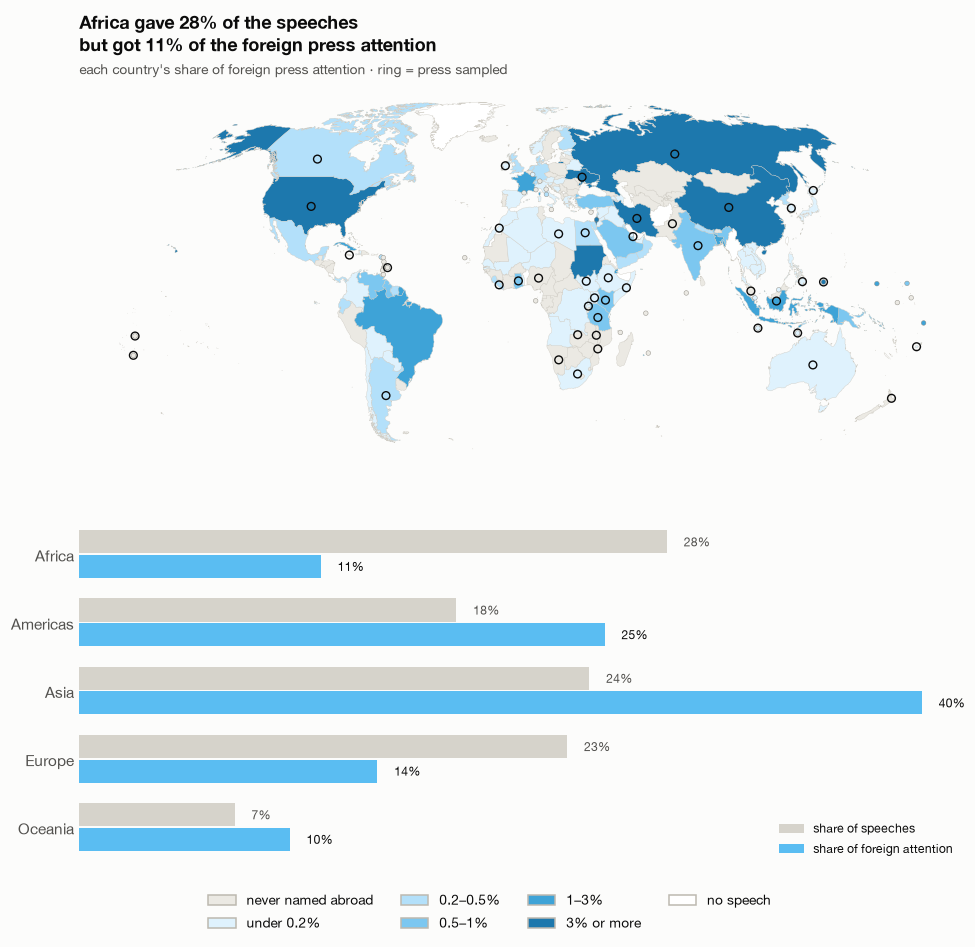

,share of speakers,share of foreign attention,attention per speaker
region,,,
Africa,28%,11%,0.41
Europe,23%,14%,0.61
Oceania,7%,10%,1.36
Americas,18%,25%,1.39
Asia,24%,40%,1.65


In [13]:
# by region: share of the speakers against share of the foreign attention
reg = speeches[speeches.status.isin(["member_state", "observer_state"])].groupby("region").size()
out = pd.DataFrame({"share of speakers": reg / reg.sum(), "share of foreign attention": att.groupby("region").foreign_share.sum() / att.foreign_share.sum()}).fillna(0)
out["attention per speaker"] = out["share of foreign attention"] / out["share of speakers"]
africa = out.loc['Africa']
attention = dict(zip(speeches.set_index("slug").iso3.reindex(att.slug), att.foreign_share))
bins = [0, 0.002, 0.005, 0.01, 0.03, 1]
steps = ["#dff2fd", "#b3e0fa", "#7cc7f0", "#3ea3d7", "#1d78ad"]
labels = ["under 0.2%", "0.2–0.5%", "0.5–1%", "1–3%", "3% or more"]
colour_of = {iso: NOT_RAISED for iso in speeches.iso3} | {iso: steps[np.searchsorted(bins, v, side="right") - 1] for iso, v in attention.items() if v > 0}

ne_name = {**dict(zip(world.NAME, world.ISO_A3_EH)), **dict(zip(world.ADMIN, world.ISO_A3_EH)),
           "United States": "USA", "Russia": "RUS", "South Korea": "KOR", "Iran": "IRN", "Tanzania": "TZA"}
panel = [ne_name.get(p["country"]) for p in D["press"]["attention"]["panel"]]
print("news countries not placed on the map:", [p["country"] for p, iso in zip(D["press"]["attention"]["panel"], panel) if iso is None])
fig, (ax, bx) = plt.subplots(2, 1, figsize=SQUARE, gridspec_kw={"height_ratios": [1.5, 1]})
world_map(ax, colour_of)
ring = world[world.ISO_A3_EH.isin(panel)].representative_point()
ax.scatter(ring.x, ring.y, s=26, facecolors="none", edgecolors=INK, linewidths=0.9, zorder=4)
finalize(ax, f"Africa gave {africa['share of speakers']:.0%} of the speeches\nbut got {africa['share of foreign attention']:.0%} of the foreign press attention",
         "each country's share of foreign press attention · ring = press sampled")
regions = ["Africa", "Americas", "Asia", "Europe", "Oceania"]
yy = np.arange(len(regions))
bx.barh(yy - 0.18, out.loc[regions, "share of speakers"], height=0.34, color="#d6d3cb", label="share of speeches")
bx.barh(yy + 0.18, out.loc[regions, "share of foreign attention"], height=0.34, color=BLUE, label="share of foreign attention")
for y, r in zip(yy, regions):
    bx.text(out.at[r, "share of speakers"] + 0.008, y - 0.18, f"{out.at[r, 'share of speakers']:.0%}", va="center", fontsize=8, color=INK_2)
    bx.text(out.at[r, "share of foreign attention"] + 0.008, y + 0.18, f"{out.at[r, 'share of foreign attention']:.0%}", va="center", fontsize=8, color=INK)
bx.set_yticks(yy, regions); bx.invert_yaxis(); bx.set_xticks([]); bx.tick_params(length=0)
for side in ("left", "bottom"):
    bx.spines[side].set_visible(False)
bx.legend(frameon=False, fontsize=8, loc="lower right")
legend(fig, [("never named abroad", NOT_RAISED)] + list(zip(labels, steps)) + [("no speech", NO_SPEECH)])
plt.tight_layout(rect=(0, 0.07, 1, 1)); show_fig(fig, "4c_press_attention_map")

out.sort_values("attention per speaker").style.format("{:.0%}", subset=["share of speakers", "share of foreign attention"]).format("{:.2f}", subset=["attention per speaker"])

In [14]:
# every issue in the scatter, with its press-to-podium ratio
pi.sort_values("ratio", ascending=False)[["issue", "podium_per_1000", "press_per_1000", "ratio", "low", "high", "verdict"]].reset_index(drop=True).style.format(
    {"podium_per_1000": "{:.2f}", "press_per_1000": "{:.2f}", "ratio": "×{:.1f}", "low": "×{:.1f}", "high": "×{:.1f}"})

,issue,podium_per_1000,press_per_1000,ratio,low,high,verdict
0,Iran and the Gulf war,0.53,4.28,×8.1,×5.2,×10.9,more press
1,Gaza,0.39,0.93,×2.4,×1.7,×3.1,more press
2,Gaza or Palestine,1.23,2.30,×1.9,×1.4,×2.3,more press
3,Palestinian statehood,0.26,0.48,×1.8,×1.2,×2.6,more press
4,Ukraine,0.66,1.06,×1.6,×1.1,×2.1,more press
5,Debt,0.29,0.46,×1.6,×0.8,×2.4,too close to call
6,Artificial intelligence,1.11,1.65,×1.5,×1.1,×2.0,more press
7,Sanctions,0.20,0.26,×1.3,×0.9,×1.8,too close to call
8,Nuclear weapons,0.21,0.25,×1.2,×0.7,×1.8,too close to call
9,Climate change,1.75,1.88,×1.1,×0.8,×1.4,too close to call


**cross-check: does Africa's low share depend on how attention is counted?** three simpler counts from the raw news file, with no outlet weighting. the low share holds in each. it is starkest in outlets outside Africa, which is the fairer test of whether the rest of the world heard Africa. 18 of the 43 news countries are African, and their outlets mostly write about their own region.

In [15]:
from unga_speeches.analysis import mentions
news = press._outside(press.load_news(D["session"]))
home_of = {r["outlet"]: r["country"] for r in press._registry()}
region_of = dict(zip(speeches.iso3, speeches.region))
raw, outside, per_country = Counter(), Counter(), {}
for n in news:
    for p in n["paragraphs"]:
        for iso in mentions.named(p):
            if iso in region_of:
                raw[region_of[iso]] += 1
                outside[region_of[iso]] += region_of[iso] != n.get("base_region")
                per_country.setdefault(home_of[n["outlet"]], Counter())[iso] += 1
votes = Counter()
for country, c in per_country.items():
    own = next(iter(mentions.named(country)), None)
    c = {i: k for i, k in c.items() if i != own}
    if sum(c.values()) >= 10:
        for i, k in c.items():
            votes[region_of[i]] += k / sum(c.values())
norm = lambda c: pd.Series(c) / sum(c.values())
pd.DataFrame({"share of speakers": out["share of speakers"], "page measure": out["share of foreign attention"],
              "one vote per news country": norm(votes), "every paragraph, unweighted": norm(raw), "outlets outside the region only": norm(outside)}
             ).loc[["Africa", "Americas", "Asia", "Europe", "Oceania"]].style.format("{:.0%}")

,share of speakers,page measure,one vote per news country,"every paragraph, unweighted",outlets outside the region only
Africa,28%,11%,10%,21%,3%
Americas,18%,25%,21%,21%,12%
Asia,24%,40%,44%,40%,62%
Europe,23%,14%,16%,14%,21%
Oceania,7%,10%,9%,4%,1%


## caveats

- **issues are found by word lists**, not by reading. a speech that names "the climate" in passing counts the same as one about nothing else.
- **income groups in Natural Earth are an old snapshot** of the World Bank's list. a few countries have moved since.
- **the NATO and BRICS lists are typed in by hand** in this notebook. the result is a comparison of members, not of how they vote.
- **the press sample is 42 news countries and 69 outlets.** it is weighted toward English-language outlets, and the page explains how it was chosen.
- **the press issue rates pool every article**, so the outlets that wrote most weigh most. Fox News and CNN supply 137 of the 342 paragraphs that name Iran, and most news countries never mention most issues.
- **small states are drawn as dots** on the maps, because their shapes are too small to see.